In [49]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_PATH = PROJECT_ROOT / "data" / "crop_yield.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Year range:", df["Crop_Year"].min(), "-", df["Crop_Year"].max())
print("Number of crops:", df["Crop"].nunique())
print("Missing values:", df.isnull().sum().sum())

df.head()


Dataset shape: (19689, 10)
Year range: 1997 - 2020
Number of crops: 55
Missing values: 0


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [50]:
# Features used by our current V1 model
features = [
    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

target = "Yield"

print("Input features:")
for feature in features:
    print("-", feature)

print("\nTarget:", target)

Input features:
- Crop
- Crop_Year
- Season
- State
- Annual_Rainfall
- Fertilizer
- Pesticide

Target: Yield


In [51]:
df[["Area", "Production", "Yield"]].describe().round(2)

,Area,Production,Yield
count,19689.00,1.968900e+04,19689.00
mean,179926.57,1.643594e+07,79.95
std,732828.68,2.630568e+08,878.31
min,0.50,0.000000e+00,0.00
25%,1390.00,1.393000e+03,0.60
50%,9317.00,1.380400e+04,1.03
75%,75112.00,1.227180e+05,2.39
max,50808100.00,6.326000e+09,21105.00


In [52]:
# Compare recorded yield with Production / Area
valid = df["Area"] > 0

calculated_yield = (
    df.loc[valid, "Production"] / df.loc[valid, "Area"]
)

comparison = pd.DataFrame({
    "Recorded_Yield": df.loc[valid, "Yield"],
    "Calculated_Yield": calculated_yield
})

comparison["Absolute_Difference"] = abs(
    comparison["Recorded_Yield"] - comparison["Calculated_Yield"]
)

comparison.describe().round(4)

,Recorded_Yield,Calculated_Yield,Absolute_Difference
count,19689.0000,19689.0000,19689.0000
mean,79.9540,83.8408,5.9310
std,878.3062,923.5971,87.6406
min,0.0000,0.0000,0.0000
25%,0.6000,0.5959,0.0138
50%,1.0300,1.0357,0.0559
75%,2.3889,2.4634,0.1721
max,21105.0000,21105.0000,3733.9933


In [53]:
nonzero = comparison[comparison["Recorded_Yield"] > 0].copy()

nonzero["Percentage_Difference"] = (
    nonzero["Absolute_Difference"]
    / nonzero["Recorded_Yield"]
    * 100
)

for threshold in [10, 25, 50, 100]:
    percentage = (
        nonzero["Percentage_Difference"].gt(threshold).mean() * 100
    )
    print(f"Difference greater than {threshold}%: {percentage:.2f}%")

Difference greater than 10%: 31.95%
Difference greater than 25%: 10.78%
Difference greater than 50%: 3.13%
Difference greater than 100%: 0.64%


In [54]:
comparison.sort_values(
    "Absolute_Difference",
    ascending=False
).head(10)

,Recorded_Yield,Calculated_Yield,Absolute_Difference
974,12368.609440,8634.616186,3733.993254
18128,13532.986670,16514.416776,2981.430106
2809,11782.472500,14544.901777,2762.429277
2483,12012.762500,14741.362764,2728.600264
3836,13712.573080,16251.862395,2539.289315
6063,8795.260556,11270.005810,2474.745254
4479,12467.607500,14751.159196,2283.551696
1722,8486.539565,10753.896206,2267.356641
18561,11250.412500,13406.563355,2156.150855
1228,9524.628235,11495.016207,1970.387972


In [55]:
feature_review = pd.DataFrame({
    "Feature": [
        "Crop",
        "Crop_Year",
        "Season",
        "State",
        "Annual_Rainfall",
        "Fertilizer",
        "Pesticide"
    ],
    "Available_before_season": [
        "Usually yes",
        "Yes",
        "Yes",
        "Yes",
        "Not necessarily",
        "Depends on scenario",
        "Depends on scenario"
    ],
    "Concern": [
        "User must select the crop",
        "Future years are outside our training period",
        "User must select the season",
        "User must select the state",
        "Actual annual rainfall may not be known yet",
        "Future input quantities may not be decided",
        "Future input quantities may not be decided"
    ]
})

feature_review

,Feature,Available_before_season,Concern
0,Crop,Usually yes,User must select the crop
1,Crop_Year,Yes,Future years are outside our training period
2,Season,Yes,User must select the season
3,State,Yes,User must select the state
4,Annual_Rainfall,Not necessarily,Actual annual rainfall may not be known yet
5,Fertilizer,Depends on scenario,Future input quantities may not be decided
6,Pesticide,Depends on scenario,Future input quantities may not be decided


In [56]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np

# Define features and target
features = [
    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

target = "Yield"

# Chronological split
train_df = df[df["Crop_Year"] <= 2017].copy()
test_df = df[df["Crop_Year"].isin([2018, 2019])].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 17510
Testing records: 2142


In [57]:
# Define feature groups
categorical_features = ["Crop", "Season", "State"]

numerical_features = [
    "Crop_Year",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

# Preprocessing
preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "numerical",
        StandardScaler(),
        numerical_features
    )
])

# Random Forest pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "regressor",
        RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
])

# Train using log-transformed yield
baseline_model.fit(X_train, np.log1p(y_train))

# Predict and convert back to original scale
y_pred = np.expm1(baseline_model.predict(X_test))
y_pred = np.maximum(y_pred, 0)

# Evaluate
print("Baseline MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("Baseline RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("Baseline R²:", round(r2_score(y_test, y_pred), 4))

Baseline MAE: 10.6382
Baseline RMSE: 150.348
Baseline R²: 0.9692


In [58]:
from sklearn.ensemble import GradientBoostingRegressor

# Create the Gradient Boosting pipeline
gb_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "regressor",
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        )
    )
])

# Train on log-transformed yield
gb_model.fit(X_train, np.log1p(y_train))

# Predict on the same test set
gb_pred = np.expm1(gb_model.predict(X_test))
gb_pred = np.maximum(gb_pred, 0)

# Evaluate
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting MAE:", round(gb_mae, 4))
print("Gradient Boosting RMSE:", round(gb_rmse, 4))
print("Gradient Boosting R²:", round(gb_r2, 4))

Gradient Boosting MAE: 38.1818
Gradient Boosting RMSE: 475.4258
Gradient Boosting R²: 0.6916


In [61]:
comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    },
    {
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(y_test, gb_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, gb_pred)),
        "R2 Score": r2_score(y_test, gb_pred)
    }
])

display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,10.6382,150.3480,0.9692
1,Gradient Boosting,38.1818,475.4258,0.6916


### Model Comparison: Random Forest vs Gradient Boosting

Two regression models were evaluated using the same features and chronological train-test split.

- **Random Forest:** MAE = 10.6382, RMSE = 150.3480, R² = 0.9692.
- **Gradient Boosting:** MAE = 38.1818, RMSE = 475.4258, R² = 0.6916.

Random Forest performed substantially better across all three evaluation metrics. Therefore, the log-transformed Random Forest remains the leading candidate for the scenario-based crop yield estimation project.

Gradient Boosting was not selected because its prediction errors were considerably higher on the evaluation dataset.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

tuned_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

tuned_model.fit(X_train, np.log1p(y_train))

tuned_pred = np.expm1(tuned_model.predict(X_test))
tuned_pred = np.maximum(tuned_pred, 0)

print("Tuned Random Forest MAE:", round(mean_absolute_error(y_test, tuned_pred), 4))

print("Tuned Random Forest RMSE:", round(np.sqrt(mean_squared_error(y_test, tuned_pred)), 4))

print("Tuned Random Forest R²:", round(r2_score(y_test, tuned_pred), 4))

Tuned Random Forest MAE: 11.2942
Tuned Random Forest RMSE: 153.5448
Tuned Random Forest R²: 0.9678


In [62]:

comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    },
    {
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(y_test, gb_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, gb_pred)),
        "R2 Score": r2_score(y_test, gb_pred)
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": mean_absolute_error(y_test, tuned_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, tuned_pred)),
        "R2 Score": r2_score(y_test, tuned_pred)
    }
])

display(comparison.round(4))


,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,10.6382,150.3480,0.9692
1,Gradient Boosting,38.1818,475.4258,0.6916
2,Tuned Random Forest,11.2942,153.5448,0.9678


In [ ]:
import pandas as pd

feature_names = baseline_model.named_steps["preprocessor"].get_feature_names_out()
importances = baseline_model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

,Feature,Importance
9,categorical__Crop_Coconut,0.3935
46,categorical__Crop_Sugarcane,0.1699
37,categorical__Crop_Potato,0.0603
3,categorical__Crop_Banana,0.0478
31,categorical__Crop_Onion,0.0377
93,numerical__Fertilizer,0.0349
94,numerical__Pesticide,0.0265
49,categorical__Crop_Tapioca,0.0264
48,categorical__Crop_Sweet potato,0.0203
92,numerical__Annual_Rainfall,0.0193


In [ ]:
def get_original_feature(feature):
    feature = feature.replace("categorical__", "")
    feature = feature.replace("numerical__", "")

    for name in [
        "Annual_Rainfall", "Crop_Year", "Fertilizer", "Pesticide",
        "Crop", "Season", "State"
    ]:
        if feature == name or feature.startswith(name + "_"):
            return name

    return feature

importance_df["Original_Feature"] = importance_df["Feature"].apply(
    get_original_feature
)

grouped_importance = (
    importance_df.groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(grouped_importance.round(4))

,Original_Feature,Importance
0,Crop,0.8372
1,State,0.0621
2,Fertilizer,0.0349
3,Pesticide,0.0265
4,Annual_Rainfall,0.0193
5,Season,0.0102
6,Crop_Year,0.0098


In [ ]:
error_df = pd.DataFrame({
    "Crop": X_test["Crop"].values,
    "Actual_Yield": y_test.values,
    "Predicted_Yield": baseline_model.predict(X_test)
})

# Convert predictions from log scale back to original scale
error_df["Predicted_Yield"] = np.expm1(error_df["Predicted_Yield"])
error_df["Predicted_Yield"] = error_df["Predicted_Yield"].clip(lower=0)

error_df["Absolute_Error"] = abs(
    error_df["Actual_Yield"] - error_df["Predicted_Yield"]
)

crop_performance = (
    error_df.groupby("Crop")
    .agg(
        Records=("Actual_Yield", "count"),
        MAE=("Absolute_Error", "mean"),
        Mean_Actual_Yield=("Actual_Yield", "mean")
    )
    .sort_values("MAE", ascending=False)
)

display(crop_performance.head(10).round(4))

,Records,MAE,Mean_Actual_Yield
Crop,,,
Coconut,17,1208.1584,8834.2320
Banana,23,10.5859,38.9311
Onion,54,10.0531,18.2669
Sugarcane,52,6.9361,59.4196
Sweet potato,33,3.0750,11.4053
Tapioca,22,2.6960,19.7010
Potato,69,1.9811,12.5507
Ginger,35,1.8572,7.5884
Tobacco,39,1.8118,3.3736


In [ ]:
crop_performance = (
    error_df.groupby("Crop")
    .agg(
        Records=("Actual_Yield", "count"),
        Total_Absolute_Error=("Absolute_Error", "sum"),
        Total_Actual_Yield=("Actual_Yield", "sum")
    )
)

crop_performance["WAPE_Percent"] = (
    crop_performance["Total_Absolute_Error"]
    / crop_performance["Total_Actual_Yield"].replace(0, np.nan)
) * 100

crop_performance = crop_performance.sort_values(
    "WAPE_Percent", ascending=False
)

display(crop_performance.head(10).round(2))

,Records,Total_Absolute_Error,Total_Actual_Yield,WAPE_Percent
Crop,,,,
Cardamom,6,0.55,0.53,104.23
other oilseeds,25,29.92,52.84,56.63
Onion,54,542.86,986.41,55.03
Tobacco,39,70.66,131.57,53.70
Other Summer Pulses,5,1.80,3.40,53.09
Niger seed,21,3.89,8.20,47.49
Other Cereals,26,11.99,27.31,43.92
Moth,10,2.12,5.27,40.15
Safflower,20,4.20,10.59,39.64


In [ ]:
from sklearn.ensemble import RandomForestRegressor

simple_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

simple_model.fit(X_train, np.log1p(y_train))

simple_pred = np.expm1(simple_model.predict(X_test))
simple_pred = np.maximum(simple_pred, 0)

print("Simpler Random Forest MAE:", round(mean_absolute_error(y_test, simple_pred), 4))
print("Simpler Random Forest RMSE:", round(np.sqrt(mean_squared_error(y_test, simple_pred)), 4))
print("Simpler Random Forest R²:", round(r2_score(y_test, simple_pred), 4))

Simpler Random Forest MAE: 11.5831
Simpler Random Forest RMSE: 152.4408
Simpler Random Forest R²: 0.9683


In [63]:
simple_pred = np.expm1(simple_model.predict(X_test))
simple_pred = np.maximum(simple_pred, 0)

comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    },
    {
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(y_test, gb_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, gb_pred)),
        "R2 Score": r2_score(y_test, gb_pred)
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": mean_absolute_error(y_test, tuned_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, tuned_pred)),
        "R2 Score": r2_score(y_test, tuned_pred)
    },
    {
        "Model": "Simpler Random Forest",
        "MAE": mean_absolute_error(y_test, simple_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, simple_pred)),
        "R2 Score": r2_score(y_test, simple_pred)
    }
])

display(comparison.round(4))


,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,10.6382,150.3480,0.9692
1,Gradient Boosting,38.1818,475.4258,0.6916
2,Tuned Random Forest,11.2942,153.5448,0.9678
3,Simpler Random Forest,11.5831,152.4408,0.9683


### Model Improvement Experiments

Three alternatives were evaluated against the baseline log-transformed Random Forest using the same features and chronological evaluation split.

1. **Gradient Boosting:** Performed substantially worse than the baseline.
2. **Tuned Random Forest:** Increasing the number of trees to 200 and limiting tree depth to 20 did not improve performance.
3. **Simpler Random Forest:** Limiting tree depth to 12 also did not improve performance.

The baseline Random Forest achieved MAE = 10.6382, RMSE = 150.3480, and R² = 0.9692, outperforming all three alternatives on the evaluation set.

Therefore, the baseline remains the leading model. Feature importance and crop-level error analysis also revealed that crop identity strongly influences predictions and that performance varies considerably across crops.

**Limitation:** The 2018–2019 evaluation set has been reused for model comparisons and should not be treated as a completely untouched final test set.

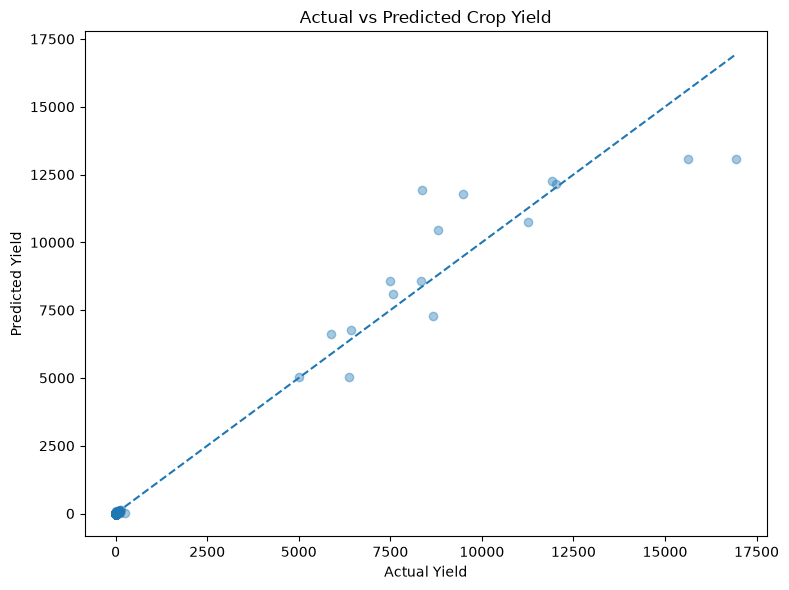

In [ ]:
import matplotlib.pyplot as plt

# Generate baseline predictions again to avoid variable-name issues
baseline_pred = np.expm1(baseline_model.predict(X_test))
baseline_pred = np.maximum(baseline_pred, 0)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, baseline_pred, alpha=0.4)

max_value = max(y_test.max(), baseline_pred.max())
plt.plot([0, max_value], [0, max_value], linestyle="--")

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Crop Yield")
plt.tight_layout()
plt.show()

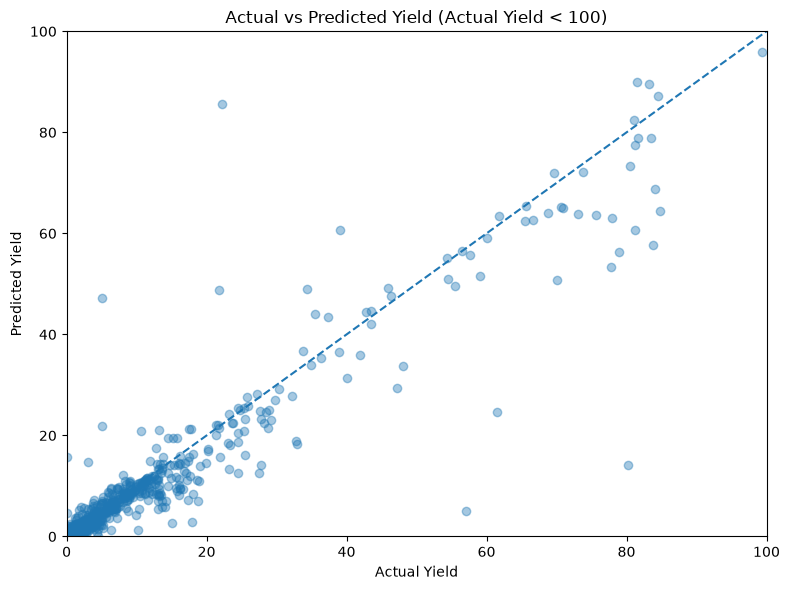

In [ ]:
ordinary = error_df[error_df["Actual_Yield"] < 100]

plt.figure(figsize=(8, 6))

plt.scatter(
    ordinary["Actual_Yield"],
    ordinary["Predicted_Yield"],
    alpha=0.4
)

plt.plot([0, 100], [0, 100], linestyle="--")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Yield (Actual Yield < 100)")
plt.tight_layout()
plt.show()

In [ ]:
error_df.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

,Crop,Actual_Yield,Predicted_Yield,Absolute_Error
355,Coconut,16935.058460,13085.556455,3849.502005
75,Coconut,8363.155000,11936.600545,3573.445545
9,Coconut,15636.632310,13071.532921,2565.099389
422,Coconut,9474.625000,11766.948523,2292.323523
647,Coconut,8795.260556,10447.800176,1652.539620
115,Coconut,8664.686667,7272.315372,1392.371295
528,Coconut,6359.690000,5042.123065,1317.566935
200,Coconut,7502.488000,8566.120777,1063.632777
612,Coconut,5882.037143,6626.649621,744.612478
461,Coconut,7582.287813,8107.811571,525.523758


In [ ]:
error_df[error_df["Crop"] == "Coconut"][
    ["Actual_Yield", "Predicted_Yield", "Absolute_Error"]
].describe().round(2)

,Actual_Yield,Predicted_Yield,Absolute_Error
count,0.0,0.0,0.0
mean,NaN,NaN,NaN
std,NaN,NaN,NaN
min,NaN,NaN,NaN
25%,NaN,NaN,NaN
50%,NaN,NaN,NaN
75%,NaN,NaN,NaN
max,NaN,NaN,NaN


In [ ]:
print("Available crops in error_df:")
print(error_df["Crop"].unique())

print("\nCoconut rows:")
print((error_df["Crop"].astype(str).str.strip().str.lower() == "coconut").sum())

Available crops in error_df:
<ArrowStringArray>
[             'Arecanut',             'Arhar/Tur',                 'Bajra',
                'Banana',             'Cashewnut',           'Castor seed',
              'Coconut ',             'Coriander',          'Cotton(lint)',
         'Cowpea(Lobia)',          'Dry chillies',                'Ginger',
                  'Gram',             'Groundnut',            'Horse-gram',
                 'Jowar',               'Linseed',                 'Maize',
                 'Mesta',     'Moong(Green Gram)',            'Niger seed',
        'Oilseeds total',                 'Onion',    'Other  Rabi pulses',
   'Other Kharif pulses',                'Potato',                  'Ragi',
     'Rapeseed &Mustard',                  'Rice',             'Safflower',
               'Sesamum',         'Small millets',              'Soyabean',
             'Sugarcane',             'Sunflower',          'Sweet potato',
               'Tapioca',               

In [ ]:
coconut_df = error_df[
    error_df["Crop"].str.strip() == "Coconut"
]

coconut_df[
    ["Actual_Yield", "Predicted_Yield", "Absolute_Error"]
].describe().round(2)

,Actual_Yield,Predicted_Yield,Absolute_Error
count,17.00,17.00,17.00
mean,8834.23,8909.97,1208.16
std,3991.92,3556.71,1212.35
min,0.00,0.00,0.00
25%,6426.82,6750.29,323.47
50%,8363.16,8566.12,744.61
75%,11263.83,11936.60,1652.54
max,16935.06,13085.56,3849.50


In [ ]:
coconut_df = coconut_df.copy()

coconut_df["Prediction_Error"] = (
    coconut_df["Predicted_Yield"] - coconut_df["Actual_Yield"]
)

coconut_df[
    ["Actual_Yield", "Predicted_Yield", "Prediction_Error"]
].sort_values("Actual_Yield")

,Actual_Yield,Predicted_Yield,Prediction_Error
1400,0.000000,0.000000,0.000000
182,5013.690000,5044.525283,30.835283
612,5882.037143,6626.649621,744.612478
528,6359.690000,5042.123065,-1317.566935
266,6426.820000,6750.286248,323.466248
200,7502.488000,8566.120777,1063.632777
461,7582.287813,8107.811571,525.523758
546,8344.984000,8566.120777,221.136777
75,8363.155000,11936.600545,3573.445545
115,8664.686667,7272.315372,-1392.371295


In [ ]:
coconut_data = df[
    df["Crop"].str.strip() == "Coconut"
]

print("Total Coconut records:", len(coconut_data))
print(
    "Coconut training records:",
    (coconut_data["Crop_Year"] <= 2017).sum()
)
print(
    "Coconut test records:",
    coconut_data["Crop_Year"].isin([2018, 2019]).sum()
)

Total Coconut records: 172
Coconut training records: 155
Coconut test records: 17


In [ ]:
coconut_train = df[
    (df["Crop"].str.strip() == "Coconut") &
    (df["Crop_Year"] <= 2017)
]

print("Coconut training yield range:")
print(coconut_train["Yield"].describe().round(2))

print("\nCoconut test yield range:")
print(
    df[
        (df["Crop"].str.strip() == "Coconut") &
        (df["Crop_Year"].isin([2018, 2019]))
    ]["Yield"].describe().round(2)
)

Coconut training yield range:
count      155.00
mean      8632.01
std       3760.76
min          0.00
25%       5721.73
50%       8486.54
75%      12051.92
max      21105.00
Name: Yield, dtype: float64

Coconut test yield range:
count       17.00
mean      8834.23
std       3991.92
min          0.00
25%       6426.82
50%       8363.16
75%      11263.83
max      16935.06
Name: Yield, dtype: float64


In [ ]:
coconut_df[
    ["Actual_Yield", "Predicted_Yield", "Prediction_Error"]
].sort_values(
    "Prediction_Error",
    key=abs,
    ascending=False
).head(5)

,Actual_Yield,Predicted_Yield,Prediction_Error
355,16935.058460,13085.556455,-3849.502005
75,8363.155000,11936.600545,3573.445545
9,15636.632310,13071.532921,-2565.099389
422,9474.625000,11766.948523,2292.323523
647,8795.260556,10447.800176,1652.539620


In [ ]:
coconut_test = test_df[
    test_df["Crop"].str.strip() == "Coconut"
].copy()

coconut_test["Actual_Yield"] = y_test.loc[
    coconut_test.index
]

coconut_test["Predicted_Yield"] = np.expm1(
    baseline_model.predict(coconut_test[features])
).clip(0)

coconut_test["Absolute_Error"] = abs(
    coconut_test["Actual_Yield"]
    - coconut_test["Predicted_Yield"]
)

coconut_test.groupby("State").agg(
    Records=("Absolute_Error", "count"),
    MAE=("Absolute_Error", "mean")
).sort_values("MAE", ascending=False).round(2)

,Records,MAE
State,,
Andhra Pradesh,2,3207.30
Puducherry,2,2932.88
Tamil Nadu,2,1076.78
Assam,2,958.95
Goa,2,674.20
Karnataka,2,642.38
Kerala,2,534.04
West Bengal,2,242.81
Chhattisgarh,1,0.00


In [ ]:
raw_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

raw_model.fit(X_train, y_train)

raw_pred = np.maximum(raw_model.predict(X_test), 0)

print("Raw-target Random Forest")
print("MAE:", round(mean_absolute_error(y_test, raw_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, raw_pred)), 4))
print("R²:", round(r2_score(y_test, raw_pred), 4))

KeyboardInterrupt: 

In [ ]:
raw_coconut_pred = raw_model.predict(
    coconut_test[features]
).clip(0)

log_coconut_pred = np.expm1(
    baseline_model.predict(coconut_test[features])
).clip(0)

print(
    "Raw-target Coconut MAE:",
    round(mean_absolute_error(
        coconut_test["Actual_Yield"],
        raw_coconut_pred
    ), 2)
)

print(
    "Log-target Coconut MAE:",
    round(mean_absolute_error(
        coconut_test["Actual_Yield"],
        log_coconut_pred
    ), 2)
)

Raw-target Coconut MAE: 1262.05
Log-target Coconut MAE: 1208.16


In [ ]:
df[["Area", "Production", "Yield"]].corr().round(3)

,Area,Production,Yield
Area,1.000,0.037,0.002
Production,0.037,1.000,0.571
Yield,0.002,0.571,1.000


In [ ]:
features_with_area = features + ["Area"]

X_train_area = train_df[features_with_area]
X_test_area = test_df[features_with_area]

area_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("numerical", StandardScaler(),
     numerical_features + ["Area"])
])

area_model = Pipeline([
    ("preprocessor", area_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

area_model.fit(X_train_area, np.log1p(y_train))

area_pred = np.expm1(area_model.predict(X_test_area))
area_pred = np.maximum(area_pred, 0)

print("With Area")
print("MAE:", round(mean_absolute_error(y_test, area_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, area_pred)), 4))
print("R²:", round(r2_score(y_test, area_pred), 4))

With Area
MAE: 11.2941
RMSE: 161.8291
R²: 0.9643


In [ ]:
crop_errors = error_df.copy()

crop_errors["Crop"] = crop_errors["Crop"].str.strip()

crop_error_summary = (
    crop_errors.groupby("Crop")
    .agg(
        Samples=("Absolute_Error", "size"),
        MAE=("Absolute_Error", "mean")
    )
    .sort_values("MAE", ascending=False)
)

crop_error_summary.head(10).round(2)

,Samples,MAE
Crop,,
Coconut,17,1208.16
Banana,23,10.59
Onion,54,10.05
Sugarcane,52,6.94
Sweet potato,33,3.08
Tapioca,22,2.70
Potato,69,1.98
Ginger,35,1.86
Tobacco,39,1.81


In [ ]:
coconut_errors = error_df[
    error_df["Crop"].str.strip() == "Coconut"
].copy()

coconut_errors["Error"] = (
    coconut_errors["Predicted_Yield"]
    - coconut_errors["Actual_Yield"]
)

coconut_errors[
    ["Actual_Yield", "Predicted_Yield", "Error", "Absolute_Error"]
].sort_values("Absolute_Error", ascending=False).round(2)

,Actual_Yield,Predicted_Yield,Error,Absolute_Error
355,16935.06,13085.56,-3849.50,3849.50
75,8363.16,11936.60,3573.45,3573.45
9,15636.63,13071.53,-2565.10,2565.10
422,9474.62,11766.95,2292.32,2292.32
647,8795.26,10447.80,1652.54,1652.54
115,8664.69,7272.32,-1392.37,1392.37
528,6359.69,5042.12,-1317.57,1317.57
200,7502.49,8566.12,1063.63,1063.63
612,5882.04,6626.65,744.61,744.61
461,7582.29,8107.81,525.52,525.52


In [ ]:
coconut_train = train_df[
    train_df["Crop"].str.strip() == "Coconut"
]

coconut_test_data = test_df[
    test_df["Crop"].str.strip() == "Coconut"
]

print("Coconut training records:", len(coconut_train))
print("Coconut test records:", len(coconut_test_data))

print("\nTraining yield statistics:")
print(coconut_train["Yield"].describe().round(2))

print("\nTest yield statistics:")
print(coconut_test_data["Yield"].describe().round(2))

Coconut training records: 155
Coconut test records: 17

Training yield statistics:
count      155.00
mean      8632.01
std       3760.76
min          0.00
25%       5721.73
50%       8486.54
75%      12051.92
max      21105.00
Name: Yield, dtype: float64

Test yield statistics:
count       17.00
mean      8834.23
std       3991.92
min          0.00
25%       6426.82
50%       8363.16
75%      11263.83
max      16935.06
Name: Yield, dtype: float64


In [ ]:
feature_importance = pd.Series(
    baseline_model.named_steps["regressor"].feature_importances_,
    index=baseline_model.named_steps["preprocessor"].get_feature_names_out()
).sort_values(ascending=False)

feature_importance.head(15).round(4)

categorical__Crop_Coconut          0.3935
categorical__Crop_Sugarcane        0.1699
categorical__Crop_Potato           0.0603
categorical__Crop_Banana           0.0478
categorical__Crop_Onion            0.0377
numerical__Fertilizer              0.0349
numerical__Pesticide               0.0265
categorical__Crop_Tapioca          0.0264
categorical__Crop_Sweet potato     0.0203
numerical__Annual_Rainfall         0.0193
categorical__Crop_Ginger           0.0110
categorical__Crop_Jute             0.0098
numerical__Crop_Year               0.0098
categorical__State_Chhattisgarh    0.0097
categorical__Crop_Mesta            0.0083
dtype: float64

In [ ]:
coconut_features = features

coconut_train = train_df[
    train_df["Crop"].str.strip() == "Coconut"
]

coconut_test_data = test_df[
    test_df["Crop"].str.strip() == "Coconut"
]

coconut_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     ["Season", "State"]),
    ("numerical", StandardScaler(),
     ["Crop_Year", "Annual_Rainfall", "Fertilizer", "Pesticide"])
])

coconut_model = Pipeline([
    ("preprocessor", coconut_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

coconut_model.fit(
    coconut_train[["Season", "State", "Crop_Year",
                   "Annual_Rainfall", "Fertilizer", "Pesticide"]],
    np.log1p(coconut_train["Yield"])
)

coconut_pred = np.expm1(
    coconut_model.predict(
        coconut_test_data[["Season", "State", "Crop_Year",
                           "Annual_Rainfall", "Fertilizer", "Pesticide"]]
    )
).clip(0)

print("Coconut-specific model MAE:",
      round(mean_absolute_error(coconut_test_data["Yield"], coconut_pred), 2))

print("Existing model Coconut MAE:",
      round(mean_absolute_error(
          coconut_test_data["Yield"],
          np.expm1(baseline_model.predict(coconut_test_data[features])).clip(0)
      ), 2))

Coconut-specific model MAE: 1256.11
Existing model Coconut MAE: 1208.16


In [ ]:
# Prepare the untouched 2020 evaluation data
final_test_df = df[df["Crop_Year"] == 2020].copy()

X_final = final_test_df[features]
y_final = final_test_df[target]

print("Final evaluation records:", len(X_final))
print("Evaluation year:", final_test_df["Crop_Year"].unique())

Final evaluation records: 37
Evaluation year: [2020]


In [ ]:
# Predict on the 2020 evaluation data
final_log_pred = baseline_model.predict(X_final)

final_pred = np.expm1(final_log_pred)
final_pred = np.maximum(final_pred, 0)

# Evaluate performance
print("Final 2020 Evaluation")
print("MAE:", round(mean_absolute_error(y_final, final_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_final, final_pred)), 4))
print("R²:", round(r2_score(y_final, final_pred), 4))


Final 2020 Evaluation
MAE: 0.8351
RMSE: 3.08
R²: 0.9458


In [ ]:
print("Actual yield statistics:")
print(y_final.describe().round(4))

print("\nCrops in the 2020 evaluation set:")
print(final_test_df["Crop"].value_counts())

print("\nActual vs predicted yields:")
final_results = pd.DataFrame({
    "Crop": final_test_df["Crop"].values,
    "Actual_Yield": y_final.values,
    "Predicted_Yield": final_pred
})

final_results["Absolute_Error"] = abs(
    final_results["Actual_Yield"] - final_results["Predicted_Yield"]
)

display(final_results.round(4))

Actual yield statistics:
count    37.0000
mean      4.4201
std      13.4112
min       0.2408
25%       0.7500
50%       1.1208
75%       2.0931
max      81.5400
Name: Yield, dtype: float64

Crops in the 2020 evaluation set:
Crop
Maize                    2
Moong(Green Gram)        2
Other Cereals            2
Potato                   2
Rice                     2
Sunflower                2
Urad                     2
other oilseeds           2
Arhar/Tur                1
Barley                   1
Garlic                   1
Gram                     1
Groundnut                1
Horse-gram               1
Masoor                   1
Moth                     1
Onion                    1
Other  Rabi pulses       1
Other Kharif pulses      1
Peas & beans (Pulses)    1
Ragi                     1
Rapeseed &Mustard        1
Sesamum                  1
Small millets            1
Soyabean                 1
Sugarcane                1
Tobacco                  1
Turmeric                 1
Wheat          

,Crop,Actual_Yield,Predicted_Yield,Absolute_Error
0,Arhar/Tur,0.8700,0.7777,0.0923
1,Barley,1.3669,1.3567,0.0102
2,Garlic,6.6035,5.9083,0.6952
3,Gram,0.7482,0.7569,0.0088
4,Groundnut,1.5217,1.1263,0.3953
5,Horse-gram,0.9691,0.8371,0.1320
6,Maize,1.9731,1.7060,0.2671
7,Maize,2.1250,1.9577,0.1673
8,Masoor,0.7515,0.7482,0.0033
9,Moong(Green Gram),0.8567,0.6323,0.2243


In [ ]:
print("Last training year:",
      train_df["Crop_Year"].max())

print("2020 included in training:",
      (train_df["Crop_Year"] == 2020).any())

print("Model training records:",
      len(X_train))

Last training year: 2017
2020 included in training: False
Model training records: 17510


In [64]:

# Compare original and whitespace-cleaned datasets
from pathlib import Path
import pandas as pd
import numpy as np

cleaned_path = PROJECT_ROOT / "data" / "crop_yield_cleaned.csv"

original_df = pd.read_csv(PROJECT_ROOT / "data" / "crop_yield.csv")
cleaned_df = pd.read_csv(cleaned_path)

# Standardize text fields consistently for a fair comparison
text_columns = ["Crop", "Season", "State"]

for col in text_columns:
    original_df[col] = original_df[col].astype("string").str.strip()
    cleaned_df[col] = cleaned_df[col].astype("string").str.strip()

features = [
    "Crop", "Crop_Year", "Season", "State",
    "Annual_Rainfall", "Fertilizer", "Pesticide"
]
target = "Yield"

def evaluate_dataset(data, dataset_name):
    train = data[data["Crop_Year"] <= 2017].copy()
    test = data[data["Crop_Year"].isin([2018, 2019])].copy()

    X_train = train[features]
    y_train = train[target]
    X_test = test[features]
    y_test = test[target]

    preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         ["Crop", "Season", "State"]),
        ("numerical", StandardScaler(),
         ["Crop_Year", "Annual_Rainfall", "Fertilizer", "Pesticide"])
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, np.log1p(y_train))
    predictions = np.expm1(model.predict(X_test))
    predictions = np.maximum(predictions, 0)

    return {
        "Dataset": dataset_name,
        "Training records": len(X_train),
        "Testing records": len(X_test),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    }

results = pd.DataFrame([
    evaluate_dataset(original_df, "Original dataset"),
    evaluate_dataset(cleaned_df, "Whitespace-cleaned dataset")
])

display(results.round(4))


,Dataset,Training records,Testing records,MAE,RMSE,R2 Score
0,Original dataset,17510,2142,10.6382,150.348,0.9692
1,Whitespace-cleaned dataset,17510,2142,10.6382,150.348,0.9692


In [65]:
# Verify the effect of whitespace cleaning

original = pd.read_csv(PROJECT_ROOT / "data" / "crop_yield.csv")
cleaned = pd.read_csv(PROJECT_ROOT / "data" / "crop_yield_cleaned.csv")

print("Original shape:", original.shape)
print("Cleaned shape:", cleaned.shape)

print("\nText values changed:")
for col in ["Crop", "Season", "State"]:
    changed = (
        original[col].astype("string")
        != cleaned[col].astype("string")
    ).sum()
    print(f"{col}: {changed}")

numeric_columns = original.select_dtypes(include="number").columns

print(
    "\nNumerical values unchanged:",
    original[numeric_columns].equals(cleaned[numeric_columns])
)

print(
    "Row count unchanged:",
    len(original) == len(cleaned)
)

Original shape: (19689, 10)
Cleaned shape: (19689, 10)

Text values changed:
Crop: 172
Season: 19689
State: 0

Numerical values unchanged: True
Row count unchanged: True


In [66]:
# Investigate records where Production and Yield disagree on zero values

zero_review = cleaned[
    (
        (cleaned["Production"] == 0) &
        (cleaned["Yield"] > 0)
    ) |
    (
        (cleaned["Production"] > 0) &
        (cleaned["Yield"] == 0)
    )
].copy()

print("Inconsistent zero-value records:", len(zero_review))

display(
    zero_review[
        [
            "Crop", "Crop_Year", "Season", "State",
            "Area", "Production", "Yield"
        ]
    ].sort_values(["Crop", "Crop_Year"]).head(20)
)

Inconsistent zero-value records: 8


,Crop,Crop_Year,Season,State,Area,Production,Yield
92,Cardamom,1997,Whole Year,West Bengal,2674.0,7,0.0
5371,Cotton(lint),2017,Kharif,Tamil Nadu,138290.0,337,0.0
5372,Cotton(lint),2017,Rabi,Tamil Nadu,43341.0,101,0.0
18226,Horse-gram,2016,Rabi,Jammu and Kashmir,1.0,0,0.4
18948,Masoor,2004,Kharif,Mizoram,0.5,0,0.4
125,Sunflower,1997,Whole Year,West Bengal,278.0,1,0.0
18005,Tobacco,2012,Kharif,Jammu and Kashmir,1.0,0,0.4
18122,Tobacco,2014,Kharif,Jammu and Kashmir,1.0,0,0.4


In [67]:

# Flag inconsistent zero-value records for review

zero_review = zero_review.copy()

zero_review["Issue"] = np.select(
    [
        (zero_review["Production"] == 0) &
        (zero_review["Yield"] > 0),

        (zero_review["Production"] > 0) &
        (zero_review["Yield"] == 0)
    ],
    [
        "Zero production but positive yield",
        "Positive production but zero yield"
    ],
    default="Other"
)

review_path = (
    PROJECT_ROOT / "docs" / "preprocessing"
    / "zero_value_records_for_review.csv"
)

review_path.parent.mkdir(parents=True, exist_ok=True)
zero_review.to_csv(review_path, index=False)

print("Records flagged:", len(zero_review))
print("\nIssue counts:")
display(zero_review["Issue"].value_counts().rename_axis("Issue").reset_index(name="Count"))

print("\nSaved review file:", review_path)
print("No rows were deleted or numerical values changed.")


Records flagged: 8

Issue counts:


,Issue,Count
0,Positive production but zero yield,4
1,Zero production but positive yield,4



Saved review file: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\preprocessing\zero_value_records_for_review.csv
No rows were deleted or numerical values changed.


In [70]:
# Recreate crop-wise IQR outlier records

outlier_frames = []

for crop, group in cleaned.groupby("Crop"):
    q1 = group["Yield"].quantile(0.25)
    q3 = group["Yield"].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flagged = group[
        (group["Yield"] < lower_bound) |
        (group["Yield"] > upper_bound)
    ].copy()

    if not flagged.empty:
        flagged["Lower_Bound"] = lower_bound
        flagged["Upper_Bound"] = upper_bound
        outlier_frames.append(flagged)

outlier_records = pd.concat(outlier_frames, ignore_index=True)

print("Total IQR-flagged records:", len(outlier_records))

Total IQR-flagged records: 749


In [71]:

# Summarize IQR-flagged records by crop

outlier_summary = (
    outlier_records.groupby("Crop")
    .agg(
        Outlier_Count=("Yield", "size"),
        Minimum_Yield=("Yield", "min"),
        Maximum_Yield=("Yield", "max"),
        Median_Yield=("Yield", "median")
    )
    .sort_values("Outlier_Count", ascending=False)
    .reset_index()
)

print("Total flagged outliers:", len(outlier_records))
print("Crops with at least one flagged outlier:", len(outlier_summary))

display(outlier_summary.head(15).round(3))


Total flagged outliers: 749
Crops with at least one flagged outlier: 52


,Crop,Outlier_Count,Minimum_Yield,Maximum_Yield,Median_Yield
0,Maize,62,4.799,989.870,6.191
1,Wheat,40,4.310,5.069,4.480
2,Dry chillies,36,5.321,14.000,7.895
3,Sannhamp,35,1.990,6.623,4.431
4,Groundnut,34,2.782,3.673,3.000
5,Tobacco,33,5.061,57.120,5.665
6,Peas & beans (Pulses),27,2.310,13.102,7.388
7,Turmeric,24,10.836,19.309,11.972
8,Arhar/Tur,24,1.560,68.230,1.679
9,Ragi,22,2.780,4.337,3.040


In [72]:

# Inspect the 20 highest-yield IQR outliers

extreme_outliers = outlier_records.sort_values(
    "Yield", ascending=False
).head(20).copy()

columns_to_show = [
    "Crop", "Crop_Year", "Season", "State",
    "Area", "Production", "Yield",
    "Lower_Bound", "Upper_Bound"
]

display(extreme_outliers[columns_to_show].round(3))


,Crop,Crop_Year,Season,State,Area,Production,Yield,Lower_Bound,Upper_Bound
146,Coconut,2014,Whole Year,Telangana,439.0,9265095,21105.000,-3103.715,21033.776
363,Maize,1997,Autumn,Maharashtra,21.0,19695,989.870,-0.490,4.734
422,Onion,2017,Kharif,Andhra Pradesh,17336.0,662728,381.420,-9.797,31.593
111,Cashewnut,2008,Whole Year,Tamil Nadu,99168.0,51667,338.549,-0.227,1.275
493,Potato,2010,Whole Year,Delhi,51.0,15862,311.020,-5.725,28.827
494,Potato,2011,Whole Year,Delhi,48.0,14928,311.000,-5.725,28.827
492,Potato,2009,Whole Year,Delhi,88.0,21999,249.990,-5.725,28.827
424,Onion,2018,Kharif,Andhra Pradesh,24750.0,677050,247.573,-9.797,31.593
427,Onion,2008,Whole Year,Haryana,2492.0,37400,178.653,-9.797,31.593
614,Sugarcane,2014,Kharif,Puducherry,1921.0,316965,165.000,-29.152,134.691


In [73]:

# Compare recorded yield with Production / Area for IQR outliers

outlier_check = outlier_records.copy()

outlier_check["Calculated_Yield"] = (
    outlier_check["Production"] / outlier_check["Area"]
)

outlier_check["Relative_Difference_Pct"] = np.where(
    outlier_check["Yield"] != 0,
    (
        abs(outlier_check["Yield"] - outlier_check["Calculated_Yield"])
        / outlier_check["Yield"].abs()
    ) * 100,
    np.nan
)

outlier_check["Difference_Over_25_Pct"] = (
    outlier_check["Relative_Difference_Pct"] > 25
)

print("Total IQR outliers:", len(outlier_check))
print(
    "Outliers with >25% ratio discrepancy:",
    int(outlier_check["Difference_Over_25_Pct"].sum())
)

display(
    outlier_check.sort_values(
        "Relative_Difference_Pct", ascending=False
    )[
        [
            "Crop", "Crop_Year", "State", "Area", "Production",
            "Yield", "Calculated_Yield", "Relative_Difference_Pct"
        ]
    ].head(20).round(3)
)


Total IQR outliers: 749
Outliers with >25% ratio discrepancy: 87


,Crop,Crop_Year,State,Area,Production,Yield,Calculated_Yield,Relative_Difference_Pct
477,Peas & beans (Pulses),2011,Jammu and Kashmir,183.0,988,2.310,5.399,133.719
111,Cashewnut,2008,Tamil Nadu,99168.0,51667,338.549,0.521,99.846
26,Arhar/Tur,2009,Jharkhand,441.0,764,68.230,1.732,97.461
411,Niger seed,2013,Chhattisgarh,63611.0,11567,4.988,0.182,96.354
746,other oilseeds,2014,Telangana,3475.0,92269,13.840,26.552,91.851
616,Sunflower,2006,Chhattisgarh,6493.0,2724,5.020,0.420,91.643
427,Onion,2008,Haryana,2492.0,37400,178.653,15.008,91.599
422,Onion,2017,Andhra Pradesh,17336.0,662728,381.420,38.228,89.977
736,other oilseeds,2011,Andhra Pradesh,6967.0,4422,5.858,0.635,89.164
424,Onion,2018,Andhra Pradesh,24750.0,677050,247.573,27.356,88.950


In [74]:

# Save the complete outlier investigation report

outlier_report_path = (
    PROJECT_ROOT / "docs" / "preprocessing"
    / "outlier_investigation_report.csv"
)

outlier_report = outlier_check.copy()

outlier_report["Review_Status"] = np.select(
    [
        outlier_report["Relative_Difference_Pct"] > 25,
        outlier_report["Relative_Difference_Pct"] > 10
    ],
    [
        "High discrepancy - verify source",
        "Moderate discrepancy - review"
    ],
    default="No large ratio discrepancy detected"
)

outlier_report.to_csv(outlier_report_path, index=False)

print("Outlier records saved:", len(outlier_report))
print("Report saved to:", outlier_report_path)
print("\nReview status counts:")

display(
    outlier_report["Review_Status"]
    .value_counts()
    .rename_axis("Review_Status")
    .reset_index(name="Count")
)


Outlier records saved: 749
Report saved to: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\preprocessing\outlier_investigation_report.csv

Review status counts:


,Review_Status,Count
0,No large ratio discrepancy detected,562
1,Moderate discrepancy - review,100
2,High discrepancy - verify source,87


In [75]:

# Final preprocessing decisions and audit summary

preprocessing_decisions = pd.DataFrame([
    {
        "Issue": "Whitespace in categorical columns",
        "Finding": "172 Crop values and 19689 Season values standardized",
        "Decision": "Applied whitespace trimming"
    },
    {
        "Issue": "Missing values",
        "Finding": "0 missing values",
        "Decision": "No imputation required"
    },
    {
        "Issue": "Duplicate records",
        "Finding": "0 exact duplicate rows",
        "Decision": "No duplicate removal required"
    },
    {
        "Issue": "Zero-value inconsistencies",
        "Finding": "8 records where Production and Yield disagree on zero",
        "Decision": "Flagged; retained pending verification"
    },
    {
        "Issue": "Crop-wise IQR outliers",
        "Finding": "749 records flagged",
        "Decision": "Retained; no automatic outlier removal"
    },
    {
        "Issue": "Yield ratio discrepancies",
        "Finding": "87 high and 100 moderate discrepancies among IQR outliers",
        "Decision": "Saved for source verification"
    },
    {
        "Issue": "Numerical data",
        "Finding": "All numerical values unchanged",
        "Decision": "Preserved original values"
    }
])

decision_path = (
    PROJECT_ROOT / "docs" / "preprocessing"
    / "preprocessing_decisions.csv"
)

preprocessing_decisions.to_csv(decision_path, index=False)

display(preprocessing_decisions)
print("\nSaved:", decision_path)



,Issue,Finding,Decision
0,Whitespace in categorical columns,172 Crop values and 19689 Season values standa...,Applied whitespace trimming
1,Missing values,0 missing values,No imputation required
2,Duplicate records,0 exact duplicate rows,No duplicate removal required
3,Zero-value inconsistencies,8 records where Production and Yield disagree ...,Flagged; retained pending verification
4,Crop-wise IQR outliers,749 records flagged,Retained; no automatic outlier removal
5,Yield ratio discrepancies,87 high and 100 moderate discrepancies among I...,Saved for source verification
6,Numerical data,All numerical values unchanged,Preserved original values



Saved: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\preprocessing\preprocessing_decisions.csv


In [76]:

# Evaluate baseline performance with and without extreme test yields

evaluation = pd.DataFrame({
    "Actual_Yield": y_test,
    "Predicted_Yield": y_pred
})

evaluation["Absolute_Error"] = (
    evaluation["Actual_Yield"] - evaluation["Predicted_Yield"]
).abs()

# Overall evaluation
overall_mae = evaluation["Absolute_Error"].mean()
overall_rmse = np.sqrt(
    np.mean(
        (evaluation["Actual_Yield"] - evaluation["Predicted_Yield"]) ** 2
    )
)

# Diagnostic subset only: actual yield below 100
ordinary = evaluation[evaluation["Actual_Yield"] < 100]

ordinary_mae = ordinary["Absolute_Error"].mean()
ordinary_rmse = np.sqrt(
    np.mean(
        (ordinary["Actual_Yield"] - ordinary["Predicted_Yield"]) ** 2
    )
)

display(pd.DataFrame([
    {
        "Evaluation": "All test records",
        "Records": len(evaluation),
        "MAE": overall_mae,
        "RMSE": overall_rmse
    },
    {
        "Evaluation": "Test records with yield < 100",
        "Records": len(ordinary),
        "MAE": ordinary_mae,
        "RMSE": ordinary_rmse
    }
]).round(4))


,Evaluation,Records,MAE,RMSE
0,All test records,2142,10.6382,150.3480
1,Test records with yield < 100,2121,0.8907,3.4973


In [77]:

# Inspect test records with actual yield >= 100

extreme_test = evaluation[
    evaluation["Actual_Yield"] >= 100
].copy()

extreme_test["Absolute_Error"] = (
    extreme_test["Actual_Yield"] -
    extreme_test["Predicted_Yield"]
).abs()

# Attach crop, year and state for interpretation
extreme_test = extreme_test.join(
    test_df[["Crop", "Crop_Year", "State"]]
)

display(
    extreme_test[
        [
            "Crop", "Crop_Year", "State",
            "Actual_Yield", "Predicted_Yield", "Absolute_Error"
        ]
    ].sort_values("Absolute_Error", ascending=False).round(3)
)


,Crop,Crop_Year,State,Actual_Yield,Predicted_Yield,Absolute_Error
5771,Coconut,2019,Andhra Pradesh,16935.058,13085.556,3849.502
5491,Coconut,2018,Puducherry,8363.155,11936.601,3573.446
5425,Coconut,2018,Andhra Pradesh,15636.632,13071.533,2565.099
5838,Coconut,2019,Puducherry,9474.625,11766.949,2292.324
6063,Coconut,2019,Tamil Nadu,8795.261,10447.800,1652.540
5531,Coconut,2018,Assam,8664.687,7272.315,1392.371
5944,Coconut,2019,Goa,6359.690,5042.123,1317.567
5616,Coconut,2018,Karnataka,7502.488,8566.121,1063.633
6028,Coconut,2019,Kerala,5882.037,6626.650,744.612
5877,Coconut,2019,Assam,7582.288,8107.812,525.524


In [78]:

# Calculate model performance separately for each crop

crop_eval = evaluation.copy()
crop_eval = crop_eval.join(test_df[["Crop"]])

crop_eval["Squared_Error"] = (
    crop_eval["Actual_Yield"] - crop_eval["Predicted_Yield"]
) ** 2

crop_summary = (
    crop_eval.groupby("Crop")
    .agg(
        Records=("Actual_Yield", "size"),
        MAE=("Absolute_Error", "mean"),
        Mean_Actual_Yield=("Actual_Yield", "mean"),
        RMSE=("Squared_Error", lambda x: np.sqrt(x.mean()))
    )
    .sort_values("MAE", ascending=False)
    .reset_index()
)

display(crop_summary.head(15).round(3))


,Crop,Records,MAE,Mean_Actual_Yield,RMSE
0,Coconut,17,1208.158,8834.232,1686.114
1,Banana,23,10.586,38.931,21.882
2,Onion,54,10.053,18.267,34.424
3,Sugarcane,52,6.936,59.420,9.804
4,Sweet potato,33,3.075,11.405,4.515
5,Tapioca,22,2.696,19.701,3.576
6,Potato,69,1.981,12.551,3.315
7,Ginger,35,1.857,7.588,3.039
8,Tobacco,39,1.812,3.374,8.379
9,Mesta,21,1.620,4.839,2.718


In [79]:

# Compare evaluation metrics with and without Coconut

without_coconut = evaluation.loc[
    test_df["Crop"].str.strip().ne("Coconut")
]

def calculate_metrics(actual, predicted, label):
    return {
        "Evaluation": label,
        "Records": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted)
    }

comparison_coconut = pd.DataFrame([
    calculate_metrics(
        evaluation["Actual_Yield"],
        evaluation["Predicted_Yield"],
        "All crops"
    ),
    calculate_metrics(
        without_coconut["Actual_Yield"],
        without_coconut["Predicted_Yield"],
        "Excluding Coconut (diagnostic only)"
    )
])

display(comparison_coconut.round(4))


,Evaluation,Records,MAE,RMSE,R2 Score
0,All crops,2142,10.6382,150.3480,0.9692
1,Excluding Coconut (diagnostic only),2125,1.0580,6.4434,0.7615


In [80]:

# Inspect predictions for Coconut

coconut_eval = evaluation.join(test_df[["Crop", "Crop_Year", "State"]])

coconut_eval = coconut_eval[
    coconut_eval["Crop"].str.strip() == "Coconut"
].copy()

coconut_eval["Error"] = (
    coconut_eval["Predicted_Yield"] - coconut_eval["Actual_Yield"]
)

coconut_eval["Absolute_Error"] = coconut_eval["Error"].abs()

display(
    coconut_eval[
        [
            "Crop_Year",
            "State",
            "Actual_Yield",
            "Predicted_Yield",
            "Error",
            "Absolute_Error"
        ]
    ].sort_values("Absolute_Error", ascending=False).round(3)
)


,Crop_Year,State,Actual_Yield,Predicted_Yield,Error,Absolute_Error
5771,2019,Andhra Pradesh,16935.058,13085.556,-3849.502,3849.502
5491,2018,Puducherry,8363.155,11936.601,3573.446,3573.446
5425,2018,Andhra Pradesh,15636.632,13071.533,-2565.099,2565.099
5838,2019,Puducherry,9474.625,11766.949,2292.324,2292.324
6063,2019,Tamil Nadu,8795.261,10447.800,1652.540,1652.540
5531,2018,Assam,8664.687,7272.315,-1392.371,1392.371
5944,2019,Goa,6359.690,5042.123,-1317.567,1317.567
5616,2018,Karnataka,7502.488,8566.121,1063.633,1063.633
6028,2019,Kerala,5882.037,6626.650,744.612,744.612
5877,2019,Assam,7582.288,8107.812,525.524,525.524


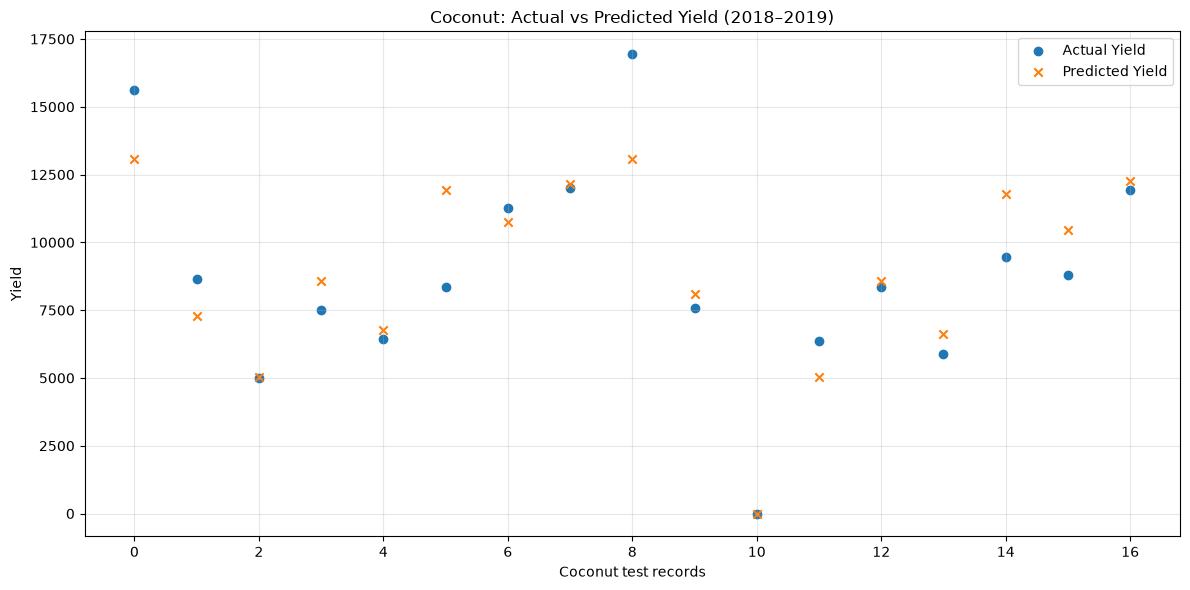

In [81]:

# Visual comparison: actual vs predicted Coconut yield

coconut_plot = coconut_eval.sort_values(
    ["Crop_Year", "State"]
).copy()

plt.figure(figsize=(12, 6))

plt.scatter(
    range(len(coconut_plot)),
    coconut_plot["Actual_Yield"],
    label="Actual Yield",
    marker="o"
)

plt.scatter(
    range(len(coconut_plot)),
    coconut_plot["Predicted_Yield"],
    label="Predicted Yield",
    marker="x"
)

plt.xlabel("Coconut test records")
plt.ylabel("Yield")
plt.title("Coconut: Actual vs Predicted Yield (2018–2019)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [82]:

# Inspect input features for the five largest Coconut prediction errors

largest_errors = coconut_eval.nlargest(5, "Absolute_Error")

coconut_features = test_df.loc[
    largest_errors.index,
    [
        "Crop",
        "Crop_Year",
        "Season",
        "State",
        "Annual_Rainfall",
        "Fertilizer",
        "Pesticide"
    ]
].copy()

coconut_features["Actual_Yield"] = largest_errors["Actual_Yield"]
coconut_features["Predicted_Yield"] = largest_errors["Predicted_Yield"]
coconut_features["Absolute_Error"] = largest_errors["Absolute_Error"]

display(coconut_features.round(3))


,Crop,Crop_Year,Season,State,Annual_Rainfall,Fertilizer,Pesticide,Actual_Yield,Predicted_Yield,Absolute_Error
5771,Coconut,2019,Whole Year,Andhra Pradesh,899.2,17867677.52,38489.99,16935.058,13085.556,3849.502
5491,Coconut,2018,Whole Year,Puducherry,1693.9,304449.40,656.95,8363.155,11936.601,3573.446
5425,Coconut,2018,Whole Year,Andhra Pradesh,1220.5,16954766.00,36585.50,15636.632,13071.533,2565.099
5838,Coconut,2019,Whole Year,Puducherry,1317.0,318958.32,687.09,9474.625,11766.949,2292.324
6063,Coconut,2019,Whole Year,Tamil Nadu,910.1,75391475.60,162405.95,8795.261,10447.800,1652.540


In [83]:

# Check Coconut training records by state

coconut_train = train_df[
    train_df["Crop"].str.strip() == "Coconut"
].copy()

state_history = (
    coconut_train.groupby("State")
    .agg(
        Training_Records=("Yield", "size"),
        First_Year=("Crop_Year", "min"),
        Last_Year=("Crop_Year", "max"),
        Mean_Yield=("Yield", "mean"),
        Min_Yield=("Yield", "min"),
        Max_Yield=("Yield", "max")
    )
    .sort_values("Training_Records", ascending=False)
    .reset_index()
)

display(state_history.round(3))


,State,Training_Records,First_Year,Last_Year,Mean_Yield,Min_Yield,Max_Yield
0,Kerala,21,1997,2017,6281.169,5304.749,6884.551
1,West Bengal,21,1997,2017,12554.349,11972.035,13592.128
2,Assam,20,1997,2017,7091.413,5238.052,9156.942
3,Karnataka,20,1998,2017,6498.231,4164.716,9984.488
4,Puducherry,18,1999,2017,11625.436,9619.110,14410.517
5,Andhra Pradesh,17,2000,2017,11199.411,7717.768,14794.630
6,Goa,15,1998,2017,4956.860,4867.380,5087.315
7,Tamil Nadu,14,2002,2017,11375.785,7781.806,14134.659
8,Chhattisgarh,6,2008,2015,0.000,0.000,0.000
9,Telangana,2,2013,2014,18679.500,16254.000,21105.000


In [84]:

# Examine historical Coconut yields in the two states
# with the largest prediction errors

states_to_check = ["Andhra Pradesh", "Puducherry"]

coconut_history = coconut_train[
    coconut_train["State"].isin(states_to_check)
].sort_values(["State", "Crop_Year"])

display(
    coconut_history[
        [
            "State",
            "Crop_Year",
            "Annual_Rainfall",
            "Fertilizer",
            "Pesticide",
            "Yield"
        ]
    ].round(3).to_string(index=False)
)


'         State  Crop_Year  Annual_Rainfall  Fertilizer  Pesticide     Yield\nAndhra Pradesh       2000          935.600 10076757.82   26687.96  9101.814\nAndhra Pradesh       2001          928.400 10646439.72   27103.44  9057.671\nAndhra Pradesh       2002          648.100  9967898.97   26322.75  9202.626\nAndhra Pradesh       2003          826.000 10290455.70   24951.60  9524.628\nAndhra Pradesh       2004          781.800 11253167.46   21812.49 10469.714\nAndhra Pradesh       2005         1075.500 12524204.96   21931.98  7717.768\nAndhra Pradesh       2006          845.200 13415041.53   23109.46 11710.482\nAndhra Pradesh       2008          944.600 15250352.64    9595.44  9132.568\nAndhra Pradesh       2009          711.000 16289578.62   17771.97 10004.874\nAndhra Pradesh       2010         1297.000 17266303.95   24946.80 11116.998\nAndhra Pradesh       2011          861.900 17416551.84   34309.11 12604.718\nAndhra Pradesh       2012          968.700 15053610.00   30945.75 14794.630

In [85]:

# Compare Random Forest predictions with a historical-mean baseline

coconut_comparison = coconut_eval.copy()

historical_means = (
    coconut_train.groupby("State")["Yield"]
    .mean()
    .rename("Historical_Mean_Yield")
)

coconut_comparison = coconut_comparison.join(
    historical_means,
    on="State"
)

coconut_comparison["Baseline_Absolute_Error"] = (
    coconut_comparison["Actual_Yield"]
    - coconut_comparison["Historical_Mean_Yield"]
).abs()

coconut_comparison["Model_Absolute_Error"] = (
    coconut_comparison["Actual_Yield"]
    - coconut_comparison["Predicted_Yield"]
).abs()

display(
    coconut_comparison[
        [
            "Crop_Year",
            "State",
            "Actual_Yield",
            "Historical_Mean_Yield",
            "Predicted_Yield",
            "Baseline_Absolute_Error",
            "Model_Absolute_Error"
        ]
    ].round(3)
)

print(
    "Historical-mean baseline MAE:",
    round(coconut_comparison["Baseline_Absolute_Error"].mean(), 3)
)

print(
    "Random Forest MAE:",
    round(coconut_comparison["Model_Absolute_Error"].mean(), 3)
)


,Crop_Year,State,Actual_Yield,Historical_Mean_Yield,Predicted_Yield,Baseline_Absolute_Error,Model_Absolute_Error
5425,2018,Andhra Pradesh,15636.632,11199.411,13071.533,4437.221,2565.099
5491,2018,Puducherry,8363.155,11625.436,11936.601,3262.281,3573.446
5531,2018,Assam,8664.687,7091.413,7272.315,1573.273,1392.371
5598,2018,Goa,5013.690,4956.860,5044.525,56.830,30.835
5616,2018,Karnataka,7502.488,6498.231,8566.121,1004.257,1063.633
5682,2018,Kerala,6426.820,6281.169,6750.286,145.651,323.466
5714,2018,Tamil Nadu,11263.830,11375.785,10762.807,111.955,501.023
5771,2019,Andhra Pradesh,16935.058,11199.411,13085.556,5735.647,3849.502
5838,2019,Puducherry,9474.625,11625.436,11766.949,2150.811,2292.324
5877,2019,Assam,7582.288,7091.413,8107.812,490.875,525.524


Historical-mean baseline MAE: 1551.179
Random Forest MAE: 1208.158


In [86]:

# Overall comparison: Random Forest vs historical-mean baseline

coconut_model_mae = coconut_comparison["Model_Absolute_Error"].mean()

coconut_baseline_mae = (
    coconut_comparison["Baseline_Absolute_Error"].mean()
)

coconut_model_rmse = np.sqrt(
    np.mean(
        (
            coconut_comparison["Actual_Yield"]
            - coconut_comparison["Predicted_Yield"]
        ) ** 2
    )
)

coconut_baseline_rmse = np.sqrt(
    np.mean(
        (
            coconut_comparison["Actual_Yield"]
            - coconut_comparison["Historical_Mean_Yield"]
        ) ** 2
    )
)

comparison_summary = pd.DataFrame({
    "Model": ["Historical-Mean Baseline", "Random Forest"],
    "MAE": [coconut_baseline_mae, coconut_model_mae],
    "RMSE": [coconut_baseline_rmse, coconut_model_rmse]
})

display(comparison_summary.round(3))


,Model,MAE,RMSE
0,Historical-Mean Baseline,1551.179,2229.552
1,Random Forest,1208.158,1686.114


In [87]:

# Experiment: Random Forest with 300 trees

rf_300 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_300.fit(X_train, np.log1p(y_train))

pred_300 = np.expm1(rf_300.predict(X_test))
pred_300 = np.clip(pred_300, 0, None)

print("Baseline Random Forest (100 trees)")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"R²:   {r2_score(y_test, y_pred):.4f}")

print("\nRandom Forest (300 trees)")
print(f"MAE:  {mean_absolute_error(y_test, pred_300):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred_300)):.4f}")
print(f"R²:   {r2_score(y_test, pred_300):.4f}")


Baseline Random Forest (100 trees)
MAE:  10.6382
RMSE: 150.3480
R²:   0.9692

Random Forest (300 trees)
MAE:  10.7988
RMSE: 151.1103
R²:   0.9688


,Feature,Importance
0,categorical__Crop_Coconut,0.3935
1,categorical__Crop_Sugarcane,0.1699
2,categorical__Crop_Potato,0.0603
3,categorical__Crop_Banana,0.0478
4,categorical__Crop_Onion,0.0377
5,numerical__Fertilizer,0.0349
6,numerical__Pesticide,0.0265
7,categorical__Crop_Tapioca,0.0264
8,categorical__Crop_Sweet potato,0.0203
9,numerical__Annual_Rainfall,0.0193


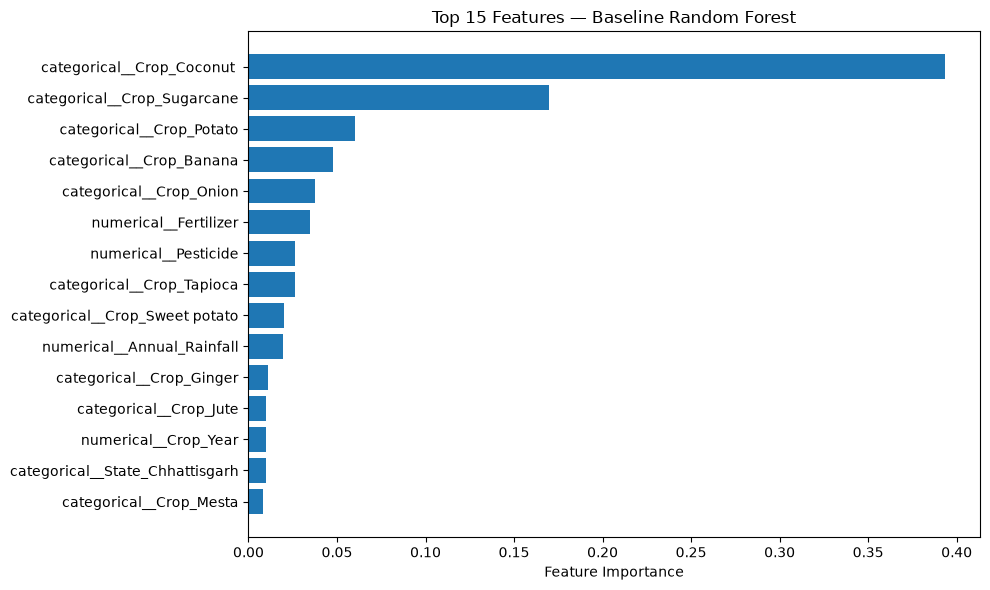

In [89]:

# Examine feature importance in the baseline Random Forest

# Rebuild the original 100-tree model so we know exactly which model we're inspecting
rf_100 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_100.fit(X_train, np.log1p(y_train))

rf_model = rf_100.named_steps["model"]
feature_names = rf_100.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

display(importance_df.head(15).round(4))

plt.figure(figsize=(10, 6))

top_features = importance_df.head(15).sort_values("Importance")

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features — Baseline Random Forest")
plt.tight_layout()
plt.show()


,Feature_Group,Importance
0,Crop,0.8372
1,State,0.0621
2,Fertilizer,0.0349
3,Pesticide,0.0265
4,Annual_Rainfall,0.0193
5,Season,0.0102
6,Crop_Year,0.0098


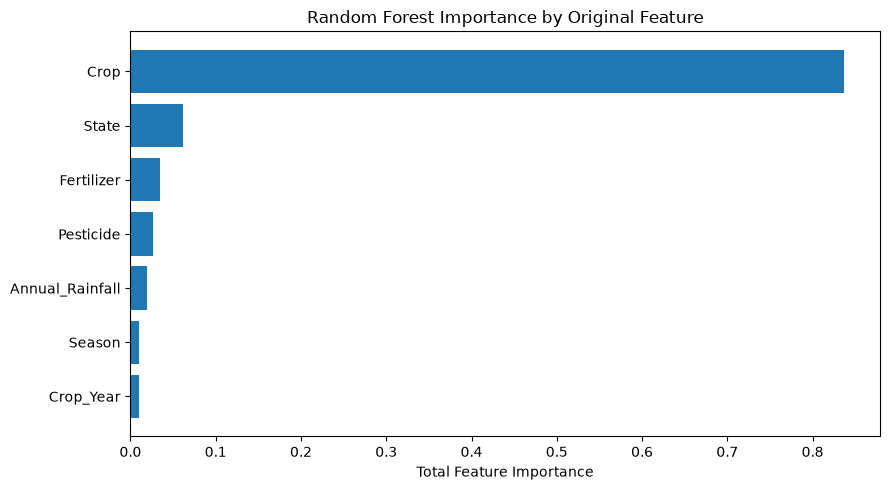

In [90]:

# Aggregate encoded feature importance by original feature group

importance_df["Feature_Group"] = importance_df["Feature"].str.extract(
    r"^(?:categorical|numerical)__([^_]+)"
)

# Use the transformer prefix to identify the original feature correctly
def get_feature_group(feature):
    name = feature.split("__", 1)[1]

    if feature.startswith("categorical__"):
        if name.startswith("Crop_"):
            return "Crop"
        elif name.startswith("State_"):
            return "State"
        elif name.startswith("Season_"):
            return "Season"

    return name

importance_df["Feature_Group"] = importance_df["Feature"].apply(
    get_feature_group
)

grouped_importance = (
    importance_df.groupby("Feature_Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(grouped_importance.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    grouped_importance.sort_values("Importance")["Feature_Group"],
    grouped_importance.sort_values("Importance")["Importance"]
)
plt.xlabel("Total Feature Importance")
plt.title("Random Forest Importance by Original Feature")
plt.tight_layout()
plt.show()


In [91]:

# Experiment: Random Forest using Crop as the only feature

crop_only_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), ["Crop"])
])

crop_only_model = Pipeline([
    ("preprocessor", crop_only_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

crop_only_model.fit(
    X_train[["Crop"]],
    np.log1p(y_train)
)

crop_only_pred = np.expm1(
    crop_only_model.predict(X_test[["Crop"]])
)

crop_only_pred = np.clip(crop_only_pred, 0, None)

results = pd.DataFrame([
    {
        "Model": "Crop Only",
        "MAE": mean_absolute_error(y_test, crop_only_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, crop_only_pred)),
        "R2": r2_score(y_test, crop_only_pred)
    },
    {
        "Model": "Full Random Forest",
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    }
])

display(results.round(4))


,Model,MAE,RMSE,R2
0,Crop Only,34.4526,454.224,0.7185
1,Full Random Forest,10.6382,150.348,0.9692


In [92]:

# Consolidated comparison of the main model experiments

model_comparison = pd.DataFrame([
    {
        "Model": "Random Forest - 100 trees",
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    },
    {
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(y_test, gb_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, gb_pred)),
        "R2": r2_score(y_test, gb_pred)
    },
    {
        "Model": "Random Forest - 300 trees",
        "MAE": mean_absolute_error(y_test, pred_300),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_300)),
        "R2": r2_score(y_test, pred_300)
    },
    {
        "Model": "Crop Only",
        "MAE": mean_absolute_error(y_test, crop_only_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, crop_only_pred)),
        "R2": r2_score(y_test, crop_only_pred)
    }
])

display(
    model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(4)
)


,Model,MAE,RMSE,R2
0,Random Forest - 100 trees,10.6382,150.3480,0.9692
1,Random Forest - 300 trees,10.7988,151.1103,0.9688
2,Crop Only,34.4526,454.2240,0.7185
3,Gradient Boosting,38.1818,475.4258,0.6916


In [93]:

# Save the consolidated model comparison

from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

OUTPUT_DIR = PROJECT_ROOT / "docs" / "model_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = OUTPUT_DIR / "model_comparison.csv"

model_comparison.to_csv(comparison_path, index=False)

print(f"Model comparison saved to: {comparison_path}")
print("\nBest model by MAE:")
display(
    model_comparison
    .sort_values("MAE")
    .head(1)
    .round(4)
)


Model comparison saved to: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\model_evaluation\model_comparison.csv

Best model by MAE:


,Model,MAE,RMSE,R2
0,Random Forest - 100 trees,10.6382,150.348,0.9692


In [95]:

# Save a summary of model findings and limitations

findings = pd.DataFrame([
    {
        "Area": "Best Model",
        "Finding": "Random Forest with 100 trees",
        "Limitation": "Selected from experiments using the same test set"
    },
    {
        "Area": "Overall Performance",
        "Finding": "MAE=10.6382; RMSE=150.3480; R2=0.9692",
        "Limitation": "Errors are strongly affected by very high-yield records"
    },
    {
        "Area": "Feature Importance",
        "Finding": "Crop contributes 83.72% of impurity-based importance",
        "Limitation": "Importance is not evidence of causation"
    },
    {
        "Area": "Coconut Analysis",
        "Finding": "Random Forest beats the historical-mean baseline on 17 records",
        "Limitation": "Small crop-specific test sample"
    },
    {
        "Area": "Data Quality",
        "Finding": "Whitespace standardized; suspicious records flagged",
        "Limitation": "Flagged values have not all been independently verified"
    },
    {
        "Area": "Final Validation",
        "Finding": "Chronological test years were 2018 and 2019",
        "Limitation": "Test set reused during model comparisons"
    }
])

summary_path = OUTPUT_DIR / "model_findings_and_limitations.csv"
findings.to_csv(summary_path, index=False)

print(f"Findings summary saved to: {summary_path}")
display(findings)


Findings summary saved to: c:\Users\rohan\OneDrive\Desktop\LAPPY\STUDY\Data Science\Crop-Yield-Analysis\docs\model_evaluation\model_findings_and_limitations.csv


,Area,Finding,Limitation
0,Best Model,Random Forest with 100 trees,Selected from experiments using the same test set
1,Overall Performance,MAE=10.6382; RMSE=150.3480; R2=0.9692,Errors are strongly affected by very high-yiel...
2,Feature Importance,Crop contributes 83.72% of impurity-based impo...,Importance is not evidence of causation
3,Coconut Analysis,Random Forest beats the historical-mean baseli...,Small crop-specific test sample
4,Data Quality,Whitespace standardized; suspicious records fl...,Flagged values have not all been independently...
5,Final Validation,Chronological test years were 2018 and 2019,Test set reused during model comparisons
